# Sistem Rekomendasi Implicit Feedback

**Implicit feedback** menebak minat pengguna dari perilaku tidak langsung seperti jumlah klik, lama menonton, atau riwayat pembelian, bukan dari rating bintang.


In [1]:
from matplotlib.ticker import MaxNLocator

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Atur gaya tampilan grafik
sns.set_theme(style="whitegrid")

# Daftar label untuk 8 pengguna dan 5 genre film
userNames = [
  "User 0",
  "User 1",
  "User 2",
  "User 3",
  "User 4",
  "User 5",
  "User 6",
  "User 7",
]
movieNames = ["Sci-Fi", "Fantasy", "Romance", "Drama", "Action"]

# Data simulasi interaksi (8 user x 5 film)
# User 0 s.d. 3 : Kelompok penyuka Sci-Fi, Fantasy, dan Action
# User 4 s.d. 6 : Kelompok penyuka Romance dan Drama
# User 7        : Baru menonton Romance (10x) -> Target rekomendasi: Drama!
rawInteractions = [
  10, 8, 0, 0, 7,  # User 0
  9, 7, 0, 0, 8,  # User 1
  8, 9, 0, 0, 6,  # User 2
  10, 6, 0, 0, 9,  # User 3
  0, 0, 10, 9, 0,  # User 4
  0, 0, 8, 10, 0,  # User 5
  0, 0, 9, 8, 0,  # User 6
  0, 0, 10, 0, 0,  # User 7 (Target uji)
]

# Susun list menjadi matriks R berukuran (8 user, 5 item)
interactionMatrix = np.array(rawInteractions).reshape(8, 5)

print("Matriks Interaksi Awal (R):")
print(interactionMatrix)

Matriks Interaksi Awal (R):
[[10  8  0  0  7]
 [ 9  7  0  0  8]
 [ 8  9  0  0  6]
 [10  6  0  0  9]
 [ 0  0 10  9  0]
 [ 0  0  8 10  0]
 [ 0  0  9  8  0]
 [ 0  0 10  0  0]]


## 1. Alternating Least Squares (ALS)

---

### Rumus Matematis & Aturan Pembaruan (Update Rules)

Metode **Alternating Least Squares (ALS)** dari Hu, Koren, dan Volinsky (2008) memecah data interaksi menjadi **Preferensi ($p_{ui}$)** dan **Tingkat Keyakinan ($c_{ui}$)**.

**A. Nilai Preferensi ($p_{ui}$) & Keyakinan ($c_{ui}$)**
$$p_{ui} = \begin{cases} 1 & \text{jika } r_{ui} > 0 \\ 0 & \text{jika } r_{ui} = 0 \end{cases}, \qquad c_{ui} = 1 + \alpha r_{ui}$$

**B. Fungsi Objektif (Loss Function)**
$$\mathcal{L} = \min_{x_*, y_*} \sum_{u,i} c_{ui} \left(p_{ui} - x_u^T y_i\right)^2 + \lambda \left( \sum_u \|x_u\|^2 + \sum_i \|y_i\|^2 \right)$$

**C. Rumus Pembaruan Vektor (Closed-Form Solution)**
Untuk mencari nilai optimal $x_u$ dan $y_i$ secara bergantian:

- **Langkah 1 (Perbarui User $u$):**
  $$x_u = \left( Y^T Y + Y^T (C^u - I) Y + \lambda I \right)^{-1} Y^T C^u p(u)$$
- **Langkah 2 (Perbarui Item $i$):**
  $$y_i = \left( X^T X + X^T (C^i - I) X + \lambda I \right)^{-1} X^T C^i p(i)$$

---

### 2. Penjelasan Lengkap Setiap Simbol

**Indeks & Ukuran Dimensi:**

- **$u$**: Indeks untuk pengguna ke-$u$ (misalnya $u = 0, 1, 2, 3$).
- **$i$**: Indeks untuk item/film ke-$i$ (misalnya $i = 0, 1, 2, 3, 4$).
- **$k$**: Jumlah fitur tersembunyi (_latent factors_), misalnya $k = 3$ dimensi selera.

**Data & Bobot Interaksi:**

- **$R$ ($r_{ui}$)**: Matriks interaksi asli, di mana $r_{ui}$ adalah jumlah klik atau tontonan pengguna $u$ pada item $i$.
- **$P$ ($p_{ui}$)**: Matriks preferensi biner. $p_{ui} = 1$ artinya pengguna $u$ pernah berinteraksi dengan item $i$, sedangkan $p_{ui} = 0$ artinya belum pernah.
- **$p(u)$**: Vektor kolom berisi seluruh nilai preferensi milik pengguna $u$ terhadap semua item.
- **$p(i)$**: Vektor kolom berisi seluruh nilai preferensi dari semua pengguna terhadap item $i$.
- **$C$ ($c_{ui}$)**: Matriks keyakinan (_confidence_), di mana $c_{ui}$ mengukur seberapa yakin sistem bahwa pengguna $u$ menyukai item $i$.
- **$C^u$**: Matriks diagonal berukuran $(n \times n)$ yang berisi nilai keyakinan $c_{ui}$ khusus untuk pengguna $u$ pada semua item.
- **$C^i$**: Matriks diagonal berukuran $(m \times m)$ yang berisi nilai keyakinan $c_{ui}$ khusus untuk item $i$ dari semua pengguna.

**Parameter Model (Hyperparameters):**

- **$\alpha$ (Alpha)**: Konstanta pengali untuk mengatur seberapa besar kenaikan jumlah klik ($r_{ui}$) meningkatkan bobot keyakinan ($c_{ui}$).
- **$\lambda$ (Lambda)**: Konstanta regularisasi untuk menghukum angka vektor yang terlalu besar agar model tidak _overfitting_ (terlalu menghafal data).

**Matriks Fitur Tersembunyi & Operasi Aljabar:**

- **$X$ ($x_u$)**: Matriks fitur pengguna berukuran $(m \times k)$, di mana $x_u$ adalah vektor selera milik pengguna $u$.
- **$Y$ ($y_i$)**: Matriks fitur item berukuran $(n \times k)$, di mana $y_i$ adalah vektor karakteristik milik item $i$.
- **$\hat{p}_{ui} = x_u^T y_i$**: Skor prediksi preferensi pengguna $u$ terhadap item $i$ hasil perkalian titik (_dot product_) vektor $x_u$ dan $y_i$.
- **$I$**: Matriks identitas (bernilai $1$ pada diagonal utama, dan $0$ di posisi lainnya).
- **$^T$ (Transpose)**: Operasi membalik baris matriks menjadi kolom (contoh: $Y^T$ adalah transpose dari $Y$).
- **$^{-1}$ (Inverse)**: Operasi invers matriks untuk menyelesaikan persamaan linear $A x_u = b$ menjadi $x_u = A^{-1} b$.
- **$\|x_u\|^2$**: Kuadrat panjang vektor (_L2 norm_), yaitu penjumlahan kuadrat dari seluruh elemen di dalam vektor $x_u$.
- **$\mathcal{L}$**: Nilai total _Loss_ (kesalahan prediksi ditambah penalti regularisasi) yang ingin diminimalkan.

---

### 3. Contoh Perhitungan Manual (Langkah demi Langkah)

Misalkan kita memiliki **1 Pengguna ($u=0$)** dan **2 Film ($i=0$ Sci-Fi, $i=1$ Horor)** dengan parameter **$\alpha = 40$**, **$\lambda = 0.1$**, dan **$k = 1$ fitur tersembunyi**.

Data interaksi asli pengguna:

- Film 0 (Sci-Fi) ditonton **$r_{0,0} = 5$ kali**.
- Film 1 (Horor) belum pernah ditonton (**$r_{0,1} = 0$**).

---

#### **Tahap 1: Menghitung Preferensi ($p_{ui}$) dan Keyakinan ($c_{ui}$)**

Berdasarkan rumus $p_{ui}$ dan $c_{ui} = 1 + \alpha r_{ui}$:

1. **Film 0 (Sci-Fi):** Karena $r_{0,0} = 5 > 0$, maka **$p_{0,0} = 1$** dan **$c_{0,0} = 1 + (40 \times 5) = 201$**.
2. **Film 1 (Horor):** Karena $r_{0,1} = 0$, maka **$p_{0,1} = 0$** dan **$c_{0,1} = 1 + (40 \times 0) = 1$**.

Didapat vektor preferensi $p(0) = \begin{bmatrix} 1 \\ 0 \end{bmatrix}$ dan matriks diagonal keyakinan untuk User 0:
$$C^0 = \begin{bmatrix} 201 & 0 \\ 0 & 1 \end{bmatrix}$$

---

#### **Tahap 2: Langkah 1 — Menghitung Pembaruan Vektor User ($x_0$)**

Misalkan matriks karakteristik item awal adalah $Y = \begin{bmatrix} 0.5 \\ 0.2 \end{bmatrix}$. Kita mengunci $Y$ lalu menghitung nilai baru $x_0$ menggunakan rumus:
$$x_0 = \left( Y^T Y + Y^T (C^0 - I) Y + \lambda I \right)^{-1} Y^T C^0 p(0)$$

1. **Hitung $Y^T Y$:**
   $$Y^T Y = \begin{bmatrix} 0.5 & 0.2 \end{bmatrix} \begin{bmatrix} 0.5 \\ 0.2 \end{bmatrix} = (0.5)^2 + (0.2)^2 = \mathbf{0.29}$$

2. **Hitung Trik Komputasi $Y^T (C^0 - I) Y$:**
   Kurangi diagonal $C^0$ dengan identitas $I$ untuk menyisakan bobot ekstra saja (Film 1 menjadi $0$):
   $$C^0 - I = \begin{bmatrix} 201-1 & 0 \\ 0 & 1-1 \end{bmatrix} = \begin{bmatrix} 200 & 0 \\ 0 & 0 \end{bmatrix}$$
   Kalikan dari kiri ke kanan:
   $$Y^T (C^0 - I) Y = \begin{bmatrix} 0.5 & 0.2 \end{bmatrix} \begin{bmatrix} 200 & 0 \\ 0 & 0 \end{bmatrix} \begin{bmatrix} 0.5 \\ 0.2 \end{bmatrix} = \begin{bmatrix} 100 & 0 \end{bmatrix} \begin{bmatrix} 0.5 \\ 0.2 \end{bmatrix} = \mathbf{50}$$

3. **Susun Matriks $A$ (Sisi Kiri):**
   $$A = Y^T Y + Y^T (C^0 - I) Y + \lambda I = 0.29 + 50 + 0.1 = \mathbf{50.39}$$

4. **Susun Vektor Target $b$ (Sisi Kanan):**
   $$b = Y^T C^0 p(0) = \begin{bmatrix} 0.5 & 0.2 \end{bmatrix} \begin{bmatrix} 201 & 0 \\ 0 & 1 \end{bmatrix} \begin{bmatrix} 1 \\ 0 \end{bmatrix} = (0.5 \times 201 \times 1) + (0.2 \times 1 \times 0) = \mathbf{100.5}$$

5. **Dapatkan Nilai $x_0$ Baru ($x_0 = A^{-1} b$):**
   $$x_0 = \frac{100.5}{50.39} \approx \mathbf{1.994}$$

---

#### **Tahap 3: Langkah 2 — Menghitung Pembaruan Vektor Item ($y_0$ dan $y_1$)**

Sekarang kita **mengunci matriks User $X = \begin{bmatrix} 1.994 \end{bmatrix}$** yang baru didapat, lalu memperbarui karakteristik masing-masing film menggunakan rumus:
$$y_i = \left( X^T X + X^T (C^i - I) X + \lambda I \right)^{-1} X^T C^i p(i)$$

- **Hitung $X^T X$ (berlaku untuk semua item):**
  $$X^T X = (1.994)^2 \approx \mathbf{3.976}$$

**A. Pembaruan untuk Film 0 (Sci-Fi, $i=0$):**
Diketahui $C^0 = \begin{bmatrix} 201 \end{bmatrix}$ dan $p(0) = \begin{bmatrix} 1 \end{bmatrix}$:

1. **Hitung $X^T (C^0 - I) X$:**
   $$C^0 - I = 201 - 1 = 200 \implies X^T (C^0 - I) X = 1.994 \times 200 \times 1.994 \approx \mathbf{795.207}$$
2. **Susun $A$ dan $b$:**
   $$A = 3.976 + 795.207 + 0.1 = \mathbf{799.283}$$
   $$b = X^T C^0 p(0) = 1.994 \times 201 \times 1 = \mathbf{400.794}$$
3. **Dapatkan Nilai $y_0$ Baru:**
   $$y_0 = \frac{400.794}{799.283} \approx \mathbf{0.501}$$

**B. Pembaruan untuk Film 1 (Horor, $i=1$):**
Diketahui $C^1 = \begin{bmatrix} 1 \end{bmatrix}$ dan $p(1) = \begin{bmatrix} 0 \end{bmatrix}$:

1. **Hitung $X^T (C^1 - I) X$:**
   $$C^1 - I = 1 - 1 = 0 \implies X^T (C^1 - I) X = 1.994 \times 0 \times 1.994 = \mathbf{0}$$
2. **Susun $A$ dan $b$:**
   $$A = 3.976 + 0 + 0.1 = \mathbf{4.076}$$
   $$b = X^T C^1 p(1) = 1.994 \times 1 \times 0 = \mathbf{0}$$
3. **Dapatkan Nilai $y_1$ Baru:**
   $$y_1 = \frac{0}{4.076} = \mathbf{0}$$

_(Hasil pembaruan matriks item setelah 1 iterasi penuh: $Y = \begin{bmatrix} 0.501 \\ 0 \end{bmatrix}$)_

---

#### **Tahap 4: Cek Skor Prediksi ($\hat{p}_{0,i}$) & Evaluasi Loss ($\mathcal{L}$)**

Kalikan $X$ dan $Y^T$ terbaru untuk melihat hasil belajar model pada iterasi pertama:

- **Prediksi Film 0 (Sci-Fi):** $\hat{p}_{0,0} = x_0 \times y_0 = 1.994 \times 0.501 \approx \mathbf{0.999}$ (mendekati target $1$).
- **Prediksi Film 1 (Horor):** $\hat{p}_{0,1} = x_0 \times y_1 = 1.994 \times 0 = \mathbf{0.000}$ (tepat di target $0$).

Hitung nilai total error (**Loss $\mathcal{L}$**):
$$\mathcal{L} = \underbrace{201(1 - 0.999)^2 + 1(0 - 0)^2}_{\text{Error Terbobot}} + \underbrace{0.1 \left( 1.994^2 + 0.501^2 + 0^2 \right)}_{\text{Penalti Regularisasi}} \approx 0.0002 + 0.4227 = \mathbf{0.4229}$$


In [2]:
class ImplicitALS:
  """
  Implementasi Alternating Least Squares (ALS) untuk data Implicit Feedback.
  """

  def __init__(self, numFactors=3, regLambda=0.1, alpha=40, numIterations=15):
    """
    Inisialisasi hyperparameter model.

    Args:
      numFactors (int): Jumlah dimensi fitur tersembunyi (k).
      regLambda (float): Parameter regularisasi (lambda) untuk mencegah overfitting.
      alpha (float): Konstanta pengali tingkat keyakinan (alpha).
      numIterations (int): Jumlah perulangan (epoch) training.
    """
    self.numFactors = numFactors
    self.regLambda = regLambda
    self.alpha = alpha
    self.numIterations = numIterations
    self.lossHistory = []

  def fit(self, ratingMatrix):
    """
    Melatih model menggunakan matriks interaksi pengguna dan item (R).

    Args:
      ratingMatrix (np.ndarray): Matriks interaksi R berukuran (m x n).
    """
    # Notasi dimensi: m = numUsers (jumlah pengguna), n = numItems (jumlah item)
    numUsers, numItems = ratingMatrix.shape

    # Inisialisasi acak matriks latent factor: X berukuran (m x k) dan Y berukuran (n x k)
    np.random.seed(42)
    self.userFactors = np.random.normal(
      scale=0.1, size=(numUsers, self.numFactors)
    )
    self.itemFactors = np.random.normal(
      scale=0.1, size=(numItems, self.numFactors)
    )

    # =========================================================================
    # TAHAP 1: Pembentukan Matriks Preferensi (P) & Keyakinan (C)
    # =========================================================================
    # Komputasi notasi: P = I(R > 0), bernilai 1 jika r_ui > 0, selain itu 0
    prefMatrix = (ratingMatrix > 0).astype(np.float64)

    # Komputasi notasi: C = 1 + alpha * R (bobot keyakinan setiap interaksi)
    confMatrix = 1.0 + self.alpha * ratingMatrix

    # Komputasi notasi: I (Matriks identitas berukuran k x k)
    identityMatrix = np.eye(self.numFactors)

    for _ in range(self.numIterations):
      # =======================================================================
      # TAHAP 2 (LANGKAH 1): Kunci Matriks Item (Y), Perbarui Vektor User (x_u)
      # Rumus: x_u = (Y^T Y + Y^T (C^u - I) Y + lambda * I)^(-1) Y^T C^u p(u)
      # =======================================================================
      # Komputasi notasi: Y^T Y (berukuran k x k, dihitung sekali per iterasi)
      itemGram = self.itemFactors.T @ self.itemFactors

      for u in range(numUsers):
        # Komputasi notasi: C^u - I (matriks diagonal bobot ekstra khusus user u)
        confUserMinusI = np.diag(confMatrix[u] - 1.0)

        # Komputasi notasi: A = Y^T Y + Y^T (C^u - I) Y + lambda * I
        matrixA = (
            itemGram
            + (self.itemFactors.T @ confUserMinusI @ self.itemFactors)
            + (self.regLambda * identityMatrix)
        )

        # Komputasi notasi: b = Y^T C^u p(u)
        vectorB = self.itemFactors.T @ (confMatrix[u] * prefMatrix[u])

        # Komputasi notasi: x_u = A^(-1) b (menyelesaikan sistem linear A x_u = b)
        self.userFactors[u] = np.linalg.solve(matrixA, vectorB)

      # =======================================================================
      # TAHAP 3 (LANGKAH 2): Kunci Matriks User (X), Perbarui Vektor Item (y_i)
      # Rumus: y_i = (X^T X + X^T (C^i - I) X + lambda * I)^(-1) X^T C^i p(i)
      # =======================================================================
      # Komputasi notasi: X^T X (berukuran k x k, dihitung sekali per iterasi)
      userGram = self.userFactors.T @ self.userFactors

      for i in range(numItems):
        # Komputasi notasi: C^i - I (matriks diagonal bobot ekstra khusus item i)
        confItemMinusI = np.diag(confMatrix[:, i] - 1.0)

        # Komputasi notasi: A = X^T X + X^T (C^i - I) X + lambda * I
        matrixA = (
            userGram
            + (self.userFactors.T @ confItemMinusI @ self.userFactors)
            + (self.regLambda * identityMatrix)
        )

        # Komputasi notasi: b = X^T C^i p(i)
        vectorB = self.userFactors.T @ (confMatrix[:, i] * prefMatrix[:, i])

        # Komputasi notasi: y_i = A^(-1) b (menyelesaikan sistem linear A y_i = b)
        self.itemFactors[i] = np.linalg.solve(matrixA, vectorB)

      # =======================================================================
      # TAHAP 4: Evaluasi Fungsi Objektif / Loss (L)
      # Rumus: L = sum(C * (P - P_hat)^2) + lambda * (||X||^2 + ||Y||^2)
      # =======================================================================
      # Komputasi notasi: P_hat = X Y^T (matriks skor prediksi preferensi)
      predMatrix = self.userFactors @ self.itemFactors.T

      # Komputasi notasi: sum(c_ui * (p_ui - p_hat_ui)^2)
      squaredError = np.sum(confMatrix * (prefMatrix - predMatrix) ** 2)

      # Komputasi notasi: lambda * (||X||^2 + ||Y||^2)
      regPenalty = self.regLambda * (
          np.sum(self.userFactors**2) + np.sum(self.itemFactors**2)
      )

      # Simpan total Loss (L) pada iterasi ini
      self.lossHistory.append(squaredError + regPenalty)

  def predictAll(self):
    """
    Menghasilkan seluruh matriks skor prediksi preferensi (P_hat = X Y^T).
    """
    # Komputasi notasi: P_hat = X Y^T
    return self.userFactors @ self.itemFactors.T

  def recommend(self, userId, ratingMatrix, topK=2):
    """
    Memberikan daftar rekomendasi item baru yang belum pernah diklik pengguna.
    
    Args:
      userId (int): Indeks pengguna (u) yang akan diberikan rekomendasi.
      ratingMatrix (np.ndarray): Matriks interaksi asli R berukuran (m x n)
        untuk mendeteksi dan menyaring item yang sudah pernah ditonton.
      topK (int, optional): Jumlah item rekomendasi teratas yang ingin diambil.
        Default bernilai 2.

    Returns:
      tuple[np.ndarray, np.ndarray]: Tuple berisi dua array:
        - topItemIds: Indeks item rekomendasi terbaik yang diurutkan dari skor tertinggi.
        - userScores[topItemIds]: Nilai skor prediksi preferensi dari masing-masing item tersebut.
    """
    # Komputasi notasi: p_hat(u) = x_u^T Y^T (vektor skor prediksi untuk user u)
    userScores = self.predictAll()[userId].copy()

    # Masking: ubah skor item yang sudah pernah berinteraksi (r_ui > 0) menjadi -inf
    watchedItems = np.where(ratingMatrix[userId] > 0)
    userScores[watchedItems] = -np.inf

    # Urutkan indeks item dari skor prediksi tertinggi ke terendah sebanyak topK
    topItemIds = np.argsort(userScores)[::-1][:topK]
    return topItemIds, userScores[topItemIds]

In [3]:
# Inisialisasi dan latih model ALS dengan matriks interaksi R (8 user x 5 film)
alsModel = ImplicitALS(
  numFactors=2, regLambda=0.05, alpha=40, numIterations=15
)
alsModel.fit(interactionMatrix)

# Ambil 2 rekomendasi item teratas untuk User 7 (u = 7)
recIds, recScores = alsModel.recommend(
  userId=7, ratingMatrix=interactionMatrix, topK=2
)

# Tampilkan nama film beserta skor prediksi preferensinya
print("Hasil Rekomendasi untuk User 7:")
for idx, scoreVal in zip(recIds, recScores):
  print(f"- Film: {movieNames[idx]} (Skor Prediksi: {scoreVal:.3f})")

Hasil Rekomendasi untuk User 7:
- Film: Drama (Skor Prediksi: 0.959)
- Film: Action (Skor Prediksi: -0.113)


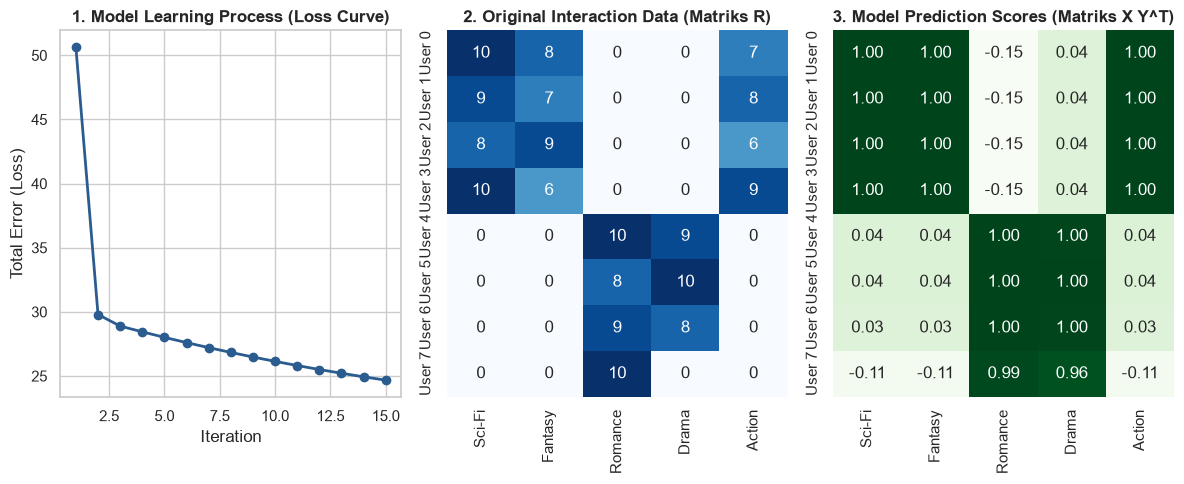

In [4]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 5))

# 1. Grafik Penurunan Loss (Error) selama Training
ax1.plot(
  range(1, alsModel.numIterations + 1),
  alsModel.lossHistory,
  marker="o",
  color="#2b5c8f",
  linewidth=2,
)
ax1.set_title(
  "1. Model Learning Process (Loss Curve)", fontsize=12, fontweight="bold"
)
ax1.set_xlabel("Iteration")
ax1.set_ylabel("Total Error (Loss)")

# 2. Heatmap Data Interaksi Asli (R)
sns.heatmap(
  interactionMatrix,
  annot=True,
  fmt="d",
  cmap="Blues",
  xticklabels=movieNames,
  yticklabels=userNames,
  ax=ax2,
  cbar=False,
)
ax2.set_title(
  "2. Original Interaction Data (Matriks R)", fontsize=12, fontweight="bold"
)

# 3. Heatmap Skor Prediksi Preferensi (X @ Y.T)
predictedMatrix = alsModel.predictAll()
sns.heatmap(
  predictedMatrix,
  annot=True,
  fmt=".2f",
  cmap="Greens",
  xticklabels=movieNames,
  yticklabels=userNames,
  ax=ax3,
  cbar=False,
)
ax3.set_title(
  "3. Model Prediction Scores (Matriks X Y^T)", fontsize=12, fontweight="bold"
)

plt.tight_layout()
plt.show()

## Bayesian Personalized Ranking (BPR)

Berbeda dengan **ALS** yang menebak skor absolut ($1$ atau $0$) per item (_pointwise_), **Bayesian Personalized Ranking (BPR)** dari Rendle dkk. (2009) berfokus pada **urutan peringkat berpasangan (_pairwise ranking_)**.

Ide utamanya sederhana: jika pengguna $u$ pernah berinteraksi dengan item $i$ (_positif_) tetapi belum pernah berinteraksi dengan item $j$ (_negatif_), maka skor prediksi item $i$ harus lebih tinggi daripada item $j$ ($\hat{x}_{ui} > \hat{x}_{uj}$).

---

### 1. Rumus Matematis & Aturan Pembaruan (SGD Update Rules)

**A. Selisih Skor Prediksi Pasangan ($\hat{x}_{uij}$)**
$$\hat{x}_{uij} = \hat{x}_{ui} - \hat{x}_{uj} = x_u^T y_i - x_u^T y_j = x_u^T (y_i - y_j)$$

**B. Fungsi Objektif (BPR-Opt Loss)**
Kita ingin memaksimalkan peluang bahwa item positif unggul atas item negatif menggunakan fungsi sigmoid $\sigma(z) = \frac{1}{1 + e^{-z}}$, atau setara dengan meminimalkan _loss_ berikut:
$$\mathcal{L}_{\text{BPR}} = -\sum_{(u, i, j) \in D_S} \ln \sigma(\hat{x}_{uij}) + \lambda \left( \|x_u\|^2 + \|y_i\|^2 + \|y_j\|^2 \right)$$

**C. Aturan Pembaruan Stochastic Gradient Descent (SGD)**
Untuk setiap sampel acak $(u, i, j)$, hitung gradien sigmoid $g_{uij} = \frac{e^{-\hat{x}_{uij}}}{1 + e^{-\hat{x}_{uij}}} = 1 - \sigma(\hat{x}_{uij})$, lalu perbarui vektor:

- **Perbarui Vektor User ($x_u$):**
  $$x_u \leftarrow x_u + \eta \left( g_{uij} \cdot (y_i - y_j) - \lambda x_u \right)$$
- **Perbarui Vektor Item Positif ($y_i$):**
  $$y_i \leftarrow y_i + \eta \left( g_{uij} \cdot x_u - \lambda y_i \right)$$
- **Perbarui Vektor Item Negatif ($y_j$):**
  $$y_j \leftarrow y_j + \eta \left( g_{uij} \cdot (-x_u) - \lambda y_j \right)$$

---

### 2. Penjelasan Lengkap Setiap Simbol

- **$D_S$**: Himpunan seluruh pasangan latihan $(u, i, j)$, di mana pengguna $u$ menyukai item $i$ ($r_{ui} > 0$) dan belum berinteraksi dengan item $j$ ($r_{uj} = 0$).
- **$x_u$**: Vektor fitur tersembunyi (_latent factor_) milik pengguna $u$ berukuran $(k,)$.
- **$y_i$**: Vektor fitur tersembunyi milik item **positif** $i$ (pernah diklik/ditonton).
- **$y_j$**: Vektor fitur tersembunyi milik item **negatif** $j$ (belum pernah diklik/ditonton).
- **$\hat{x}_{ui} = x_u^T y_i$**: Skor prediksi preferensi pengguna $u$ terhadap item positif $i$.
- **$\hat{x}_{uj} = x_u^T y_j$**: Skor prediksi preferensi pengguna $u$ terhadap item negatif $j$.
- **$\hat{x}_{uij}$**: Selisih skor antara item positif dan item negatif ($\hat{x}_{ui} - \hat{x}_{uj}$).
- **$e$**: Bilangan Euler ($\approx 2.718$), konstanta matematika yang menjadi basis fungsi eksponensial alami.
- **$\sigma(z)$**: Fungsi aktivasi Sigmoid $\frac{1}{1 + e^{-z}}$ yang mengubah selisih skor menjadi probabilitas antara $0$ hingga $1$.
- **$\ln$**: Logaritma natural (logaritma dengan basis $e$). Dalam fungsi _loss_ ($-\ln \sigma(\hat{x}_{uij})$), fungsi ini mengubah probabilitas menjadi skor penalti error positif: nilainya mendekati $0$ jika tebakan urutan sudah benar ($\sigma \to 1$), dan melonjak sangat besar jika tebakan keliru ($\sigma \to 0$).
- **$g_{uij}$**: Besar gradien kesalahan urutan ($1 - \sigma(\hat{x}_{uij})$). Nilainya mendekati $1$ jika model salah mengurutkan ($\hat{x}_{ui} < \hat{x}_{uj}$), dan mendekati $0$ jika urutan sudah benar.
- **$\eta$ (Eta)**: _Learning rate_ yang mengatur seberapa besar langkah pembaruan vektor pada setiap iterasi SGD.
- **$\lambda$ (Lambda)**: Parameter regularisasi untuk mencegah _overfitting_.

---

### 3. Contoh Perhitungan Manual (1 Langkah SGD)

Misalkan kita memiliki **1 fitur tersembunyi ($k = 1$)**, _learning rate_ **$\eta = 0.1$**, dan regularisasi **$\lambda = 0.01$**.
Diambil satu sampel pasangan untuk **User 7**:

- Item positif ($i$): **Romance** dengan vektor awal $y_i = 0.4$.
- Item negatif ($j$): **Sci-Fi** dengan vektor awal $y_j = 0.6$.
- Vektor awal **User 7**: $x_u = 0.5$.

**Langkah 1: Hitung Selisih Skor ($\hat{x}_{uij}$)**
$$\hat{x}_{ui} = 0.5 \times 0.4 = 0.20, \qquad \hat{x}_{uj} = 0.5 \times 0.6 = 0.30$$
$$\hat{x}_{uij} = 0.20 - 0.30 = \mathbf{-0.10}$$
_(Model masih keliru karena skor item negatif Sci-Fi lebih tinggi daripada item positif Romance)._

**Langkah 2: Hitung Probabilitas Sigmoid & Gradien ($g_{uij}$)**
$$\sigma(-0.10) = \frac{1}{1 + e^{0.10}} \approx 0.475$$
$$g_{uij} = 1 - 0.475 = \mathbf{0.525}$$

**Langkah 3: Perbarui Vektor $x_u$, $y_i$, dan $y_j$**

1. **User ($x_u$):**

$$x_u \leftarrow 0.5 + 0.1 \big( 0.525 \times (0.4 - 0.6) - 0.01(0.5) \big) = 0.5 + 0.1(-0.110) = \mathbf{0.489}$$

2. **Item Positif Romance ($y_i$):**

$$y_i \leftarrow 0.4 + 0.1 \big( 0.525 \times 0.5 - 0.01(0.4) \big) = 0.4 + 0.1(0.2585) = \mathbf{0.426} \quad \text{(skor naik)}$$

3. **Item Negatif Sci-Fi ($y_j$):**

$$y_j \leftarrow 0.6 + 0.1 \big( 0.525 \times (-0.5) - 0.01(0.6) \big) = 0.6 + 0.1(-0.2685) = \mathbf{0.573} \quad \text{(skor turun)}$$

Setelah 1 langkah, nilai **Romance naik** ($0.4 \to 0.426$) dan **Sci-Fi turun** ($0.6 \to 0.573$) sehingga peringkat item positif perlahan menyalip item negatif.

**Langkah 4: Hitung Nilai Error / BPR Loss ($\mathcal{L}_{\text{BPR}}$)**

Kita mengevaluasi seberapa besar kesalahan model pada pasangan $(u, i, j)$ menggunakan fungsi objektif BPR:

$$\mathcal{L}_{\text{BPR}} = -\ln \sigma(\hat{x}_{uij}) + \lambda \left( \|x_u\|^2 + \|y_i\|^2 + \|y_j\|^2 \right)$$

1. **Hitung Suku Error Peringkat ($-\ln \sigma(\hat{x}_{uij})$):**
   Dari Langkah 2 didapat $\sigma(-0.10) \approx 0.475$:
   $$-\ln(0.475) \approx -(-0.744) = \mathbf{0.744}$$

2. **Hitung Suku Penalti Regularisasi ($\lambda \left( \|x_u\|^2 + \|y_i\|^2 + \|y_j\|^2 \right)$):**
   Gunakan nilai vektor sebelum pembaruan ($x_u = 0.5$, $y_i = 0.4$, $y_j = 0.6$) dan $\lambda = 0.01$:
   $$0.01 \times \left( 0.5^2 + 0.4^2 + 0.6^2 \right) = 0.01 \times (0.25 + 0.16 + 0.36) = 0.01 \times 0.77 = \mathbf{0.0077}$$

3. **Jumlahkan Total BPR Loss:**
   $$\mathcal{L}_{\text{BPR}} = 0.744 + 0.0077 = \mathbf{0.7517}$$

_(Jika setelah banyak iterasi skor item positif jauh melampaui item negatif sehingga $\sigma(\hat{x}_{uij}) \to 1$, maka nilai $-\ln(1) = \mathbf{0}$, yang menandakan kesalahan peringkat sudah hilang)._


In [5]:
class ImplicitBPR:
  """
  Implementasi Bayesian Personalized Ranking (BPR) untuk data Implicit Feedback
  menggunakan optimasi Stochastic Gradient Descent (SGD).
  """

  def __init__(
      self, numFactors=2, learningRate=0.05, regLambda=0.01, numEpochs=250
  ):
    """
    Inisialisasi hyperparameter model BPR.

    Args:
      numFactors (int): Jumlah dimensi fitur tersembunyi (k).
      learningRate (float): Laju pembelajaran (eta) untuk pembaruan SGD.
      regLambda (float): Konstanta regularisasi (lambda) untuk mencegah overfitting.
      numEpochs (int): Jumlah perulangan penuh melewati seluruh sampel pasangan.
    """
    self.numFactors = numFactors
    self.learningRate = learningRate
    self.regLambda = regLambda
    self.numEpochs = numEpochs
    self.lossHistory = []

  def _sigmoid(self, xVal):
    """
    Menghitung fungsi aktivasi Sigmoid: sigma(x) = 1 / (1 + exp(-x)).
    """
    clippedVal = np.clip(xVal, -30.0, 30.0)
    return 1.0 / (1.0 + np.exp(-clippedVal))

  def fit(self, ratingMatrix):
    """
    Melatih model BPR dengan mengambil sampel pasangan (u, i, j) secara acak.

    Args:
      ratingMatrix (np.ndarray): Matriks interaksi asli R berukuran (m x n).
    """
    numUsers, numItems = ratingMatrix.shape

    # Inisialisasi acak matriks latent factor: X (m x k) dan Y (n x k)
    np.random.seed(42)
    self.userFactors = np.random.normal(
      scale=0.1, size=(numUsers, self.numFactors)
    )
    self.itemFactors = np.random.normal(
      scale=0.1, size=(numItems, self.numFactors)
    )

    # Kumpulkan daftar indeks item positif (r_ui > 0) dan negatif (r_uj == 0)
    userNegItems = {}
    allInteractions = []

    for u in range(numUsers):
      # [0] diambil agar mendapatkan array 1D indeks kolom
      posIds = np.where(ratingMatrix[u] > 0)[0]
      negIds = np.where(ratingMatrix[u] == 0)[0]
      userNegItems[u] = negIds

      for i in posIds:
        allInteractions.append((u, i))

    for _ in range(self.numEpochs):
      np.random.shuffle(allInteractions)
      epochLoss = 0.0

      for u, posId in allInteractions:
        if len(userNegItems[u]) == 0:
          continue

        # Pilih 1 item negatif (j) secara acak dari item yang belum ditonton user u
        negId = np.random.choice(userNegItems[u])

        # Ambil vektor saat ini: x_u, y_i (positif), dan y_j (negatif)
        userVec = self.userFactors[u].copy()
        posItemVec = self.itemFactors[posId].copy()
        negItemVec = self.itemFactors[negId].copy()

        # Komputasi notasi: x_uij = x_u^T (y_i - y_j)
        diffScores = np.dot(userVec, posItemVec - negItemVec)

        # Komputasi notasi: g_uij = 1 - sigma(x_uij)
        sigmoidProb = self._sigmoid(diffScores)
        gradCoeff = 1.0 - sigmoidProb

        # Pembaruan SGD untuk x_u, y_i, dan y_j
        self.userFactors[u] += self.learningRate * (
          gradCoeff * (posItemVec - negItemVec) - self.regLambda * userVec
        )
        self.itemFactors[posId] += self.learningRate * (
          gradCoeff * userVec - self.regLambda * posItemVec
        )
        self.itemFactors[negId] += self.learningRate * (
          gradCoeff * (-userVec) - self.regLambda * negItemVec
        )

        # Komputasi BPR Loss: -ln(sigma(x_uij)) + lambda * (||x_u||^2 + ||y_i||^2 + ||y_j||^2)
        regTerm = self.regLambda * (
          np.sum(userVec**2) + np.sum(posItemVec**2) + np.sum(negItemVec**2)
        )
        epochLoss += -np.log(sigmoidProb + 1e-10) + regTerm

      self.lossHistory.append(epochLoss / len(allInteractions))

  def predictAll(self):
    """
    Menghasilkan seluruh matriks skor peringkat prediksi (X Y^T).
    """
    return self.userFactors @ self.itemFactors.T

  def recommend(self, userId, ratingMatrix, topK=2):
    """
    Memberikan daftar rekomendasi item baru yang belum pernah diklik pengguna.

    Args:
      userId (int): Indeks pengguna (u) yang akan diberikan rekomendasi.
      ratingMatrix (np.ndarray): Matriks interaksi asli R berukuran (m x n).
      topK (int, optional): Jumlah item rekomendasi teratas. Default 2.

    Returns:
      tuple[np.ndarray, np.ndarray]: Tuple (topItemIds, skor peringkat).
    """
    userScores = self.predictAll()[userId].copy()

    # Masking item yang sudah pernah ditonton (r_ui > 0)
    watchedItems = np.where(ratingMatrix[userId] > 0)[0]
    userScores[watchedItems] = -np.inf

    topItemIds = np.argsort(userScores)[::-1][:topK]
    return topItemIds, userScores[topItemIds]


In [6]:
# Latih model BPR menggunakan interactionMatrix (8 user x 5 film)
bprModel = ImplicitBPR(
  numFactors=2, learningRate=0.05, regLambda=0.01, numEpochs=250
)
bprModel.fit(interactionMatrix)

# Ambil 2 rekomendasi teratas untuk User 7 (u = 7)
bprRecIds, bprRecScores = bprModel.recommend(
  userId=7, ratingMatrix=interactionMatrix, topK=2
)

print("\nHasil Rekomendasi BPR untuk User 7:")
for idx, scoreVal in zip(bprRecIds, bprRecScores):
  print(f"- Film: {movieNames[idx]} (Skor Peringkat: {scoreVal:.3f})")


Hasil Rekomendasi BPR untuk User 7:
- Film: Drama (Skor Peringkat: 1.961)
- Film: Fantasy (Skor Peringkat: -2.126)


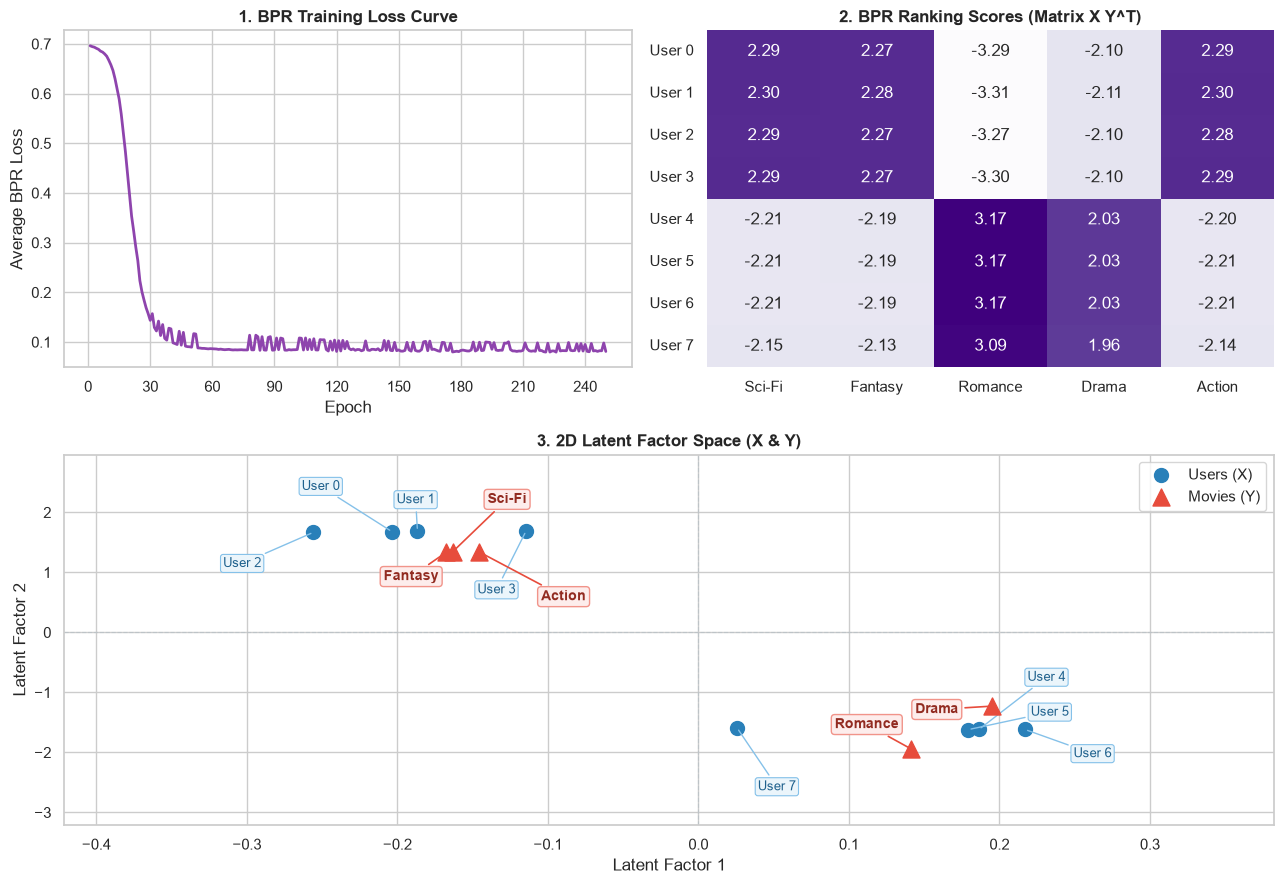

In [7]:
# Atur tata letak mosaic: baris atas berisi grafik 1 & 2, baris bawah grafik 3 melebar penuh
fig, axes = plt.subplot_mosaic(
  [["ax1", "ax2"], ["ax3", "ax3"]],
  figsize=(13, 9),
  gridspec_kw={"height_ratios": [1, 1.1]},
)

ax1 = axes["ax1"]
ax2 = axes["ax2"]
ax3 = axes["ax3"]

# 1. Grafik Penurunan BPR Loss selama Training
epochsRange = list(range(1, bprModel.numEpochs + 1))
ax1.plot(epochsRange, bprModel.lossHistory, color="#8e44ad", linewidth=2)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
ax1.set_title("1. BPR Training Loss Curve", fontsize=12, fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Average BPR Loss")

# 2. Heatmap Skor Peringkat Prediksi BPR (X Y^T)
bprPredMatrix = bprModel.predictAll()
sns.heatmap(
  bprPredMatrix,
  annot=True,
  fmt=".2f",
  cmap="Purples",
  xticklabels=movieNames,
  yticklabels=userNames,
  ax=ax2,
  cbar=False,
)
ax2.set_title(
  "2. BPR Ranking Scores (Matrix X Y^T)", fontsize=12, fontweight="bold"
)

# 3. Visualisasi 2D Latent Space (Posisi User & Film)
ax3.scatter(
  bprModel.userFactors[:, 0],
  bprModel.userFactors[:, 1],
  color="#2980b9",
  s=100,
  zorder=3,
  label="Users (X)",
)
ax3.scatter(
  bprModel.itemFactors[:, 0],
  bprModel.itemFactors[:, 1],
  color="#e74c3c",
  marker="^",
  s=150,
  zorder=4,
  label="Movies (Y)",
)

# Perbesar margin tepi plot agar label yang jauh tetap muat di dalam bingkai
ax3.margins(0.35)

# Jarak radial lebar (x, y) untuk menyebar label User yang berdempetan
userOffsets = [
  (-65, 30),  # User 0 
  (-15, 20),  # User 1 
  (-65, -25),  # User 2 
  (-35, -45),  # User 3 
  (35, 35),  # User 4 
  (45, 10),  # User 5 
  (35, -20),  # User 6 
  (15, -45),  # User 7 
]

for uIdx, uName in enumerate(userNames):
  ax3.annotate(
    uName,
    (bprModel.userFactors[uIdx, 0], bprModel.userFactors[uIdx, 1]),
    textcoords="offset points",
    xytext=userOffsets[uIdx % len(userOffsets)],
    fontsize=9.5,
    color="#1f618d",
    bbox=dict(
      boxstyle="round,pad=0.2", fc="#ebf5fb", ec="#85c1e9", lw=0.8
    ),
    arrowprops=dict(arrowstyle="-", color="#85c1e9", lw=1.0),
  )

# Jarak radial lebar untuk menyebar label Film
movieOffsets = [
  (25, 35),  # Sci-Fi
  (-45, -20),  # Fantasy
  (-55, 15),  # Romance
  (-55, -5),  # Drama
  (45, -35),  # Action
]

for iIdx, mName in enumerate(movieNames):
  ax3.annotate(
    mName,
    (bprModel.itemFactors[iIdx, 0], bprModel.itemFactors[iIdx, 1]),
    textcoords="offset points",
    xytext=movieOffsets[iIdx % len(movieOffsets)],
    fontsize=10,
    fontweight="bold",
    color="#922b21",
    bbox=dict(
      boxstyle="round,pad=0.25", fc="#fdedec", ec="#f1948a", lw=1.0
    ),
    arrowprops=dict(arrowstyle="-", color="#e74c3c", lw=1.2),
  )

# Garis sumbu pusat (0, 0) untuk membantu melihat pembagian kuadran kelompok
ax3.axhline(0, color="#bdc3c7", linestyle="--", linewidth=0.8, zorder=1)
ax3.axvline(0, color="#bdc3c7", linestyle="--", linewidth=0.8, zorder=1)

ax3.set_title(
  "3. 2D Latent Factor Space (X & Y)", fontsize=12, fontweight="bold"
)
ax3.set_xlabel("Latent Factor 1")
ax3.set_ylabel("Latent Factor 2")
ax3.legend(loc="upper right")

plt.tight_layout()
plt.show()